Membros : 

-Gabriel Faria Monteiro

-Livia Toledo Gandini

-Samuel Marques da Silva

Tema : Projeção e Análise de empregos envovlendo Inteligência Artificial em 2026 

![alt text](image.png)



In [2]:
#Importando as bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Configuração inicial


In [3]:
dataset = pd.read_csv("datasets/global_ai_jobs_2026.csv",sep = ",") #Caminho github

print(f"Visualização dataset : ")
display(dataset)
print(f"Colunas do dataset: \n{dataset.columns}")

Visualização dataset : 


,Job_ID,Job_Title,AI_Specialization,Industry,Company,Company_Size,Country,Continent,Education_Required,Experience_Level,...,Work_Life_Balance_1_10,AI_Investment_Company_Millions,Company_AI_Maturity_1_10,Job_Growth_Projection_%,Automation_Risk_%,Gender_Diversity_%_Female,Posted_Date,Application_Deadline,Record_Created,Data_Source
0,AI-03546,Business Intelligence Analyst,Computer Vision,E-commerce,Alibaba,Enterprise (5000+),Israel,Asia,Bachelor's,Executive,...,5.2,39,3.9,30.7,10.2,22.7,2035-09-16,2035-10-17,2026-08-28,Global AI Jobs Report 2026
1,AI-01969,Generative AI Engineer,Reinforcement Learning,Automotive,UiPath,Large (501-5000),United States,North America,Master's,Executive,...,7.3,499,3.9,18.1,20.7,39.8,2031-05-23,2031-06-23,2026-08-28,Global AI Jobs Report 2026
2,AI-02960,AI Software Engineer,Deep Learning,Insurance,UiPath,Enterprise (5000+),United States,North America,Postdoctoral,Executive,...,5.5,5,2.8,43.7,29.1,27.1,2034-02-07,2034-03-10,2026-08-28,Global AI Jobs Report 2026
3,AI-02384,NLP Engineer,Other,Transportation,Adobe,Large (501-5000),United States,North America,PhD,Executive,...,4.7,172,8.1,39.9,24.9,15.9,2032-07-11,2032-08-11,2026-08-28,Global AI Jobs Report 2026
4,AI-03930,AI Solutions Architect,Reinforcement Learning,Cloud Computing,Megvii,Large (501-5000),Switzerland,Europe,PhD,Executive,...,8.1,65,6.8,25.6,31.5,41.2,2036-10-04,2036-11-04,2026-08-28,Global AI Jobs Report 2026
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,AI-01197,Research Engineer,Machine Learning,E-commerce,Meta,Large (501-5000),China,Asia,PhD,Entry Level,...,8.4,170,9.3,26.4,6.3,34.1,2029-04-11,2029-05-12,2026-08-28,Global AI Jobs Report 2026
4996,AI-01820,Senior Data Scientist,Other,E-commerce,Airbnb,Enterprise (5000+),Indonesia,Asia,Master's,Entry Level,...,4.6,402,3.9,22.9,7.9,16.7,2030-12-25,2031-01-25,2026-08-28,Global AI Jobs Report 2026
4997,AI-02671,AI Cloud Engineer,NLP,Agriculture,IBM,Medium (51-500),Philippines,Asia,Master's,Entry Level,...,6.3,211,7.8,32.1,36.8,15.1,2033-04-24,2033-05-25,2026-08-28,Global AI Jobs Report 2026
4998,AI-04758,AI Policy Advisor,Machine Learning,Consulting,Toshiba,Large (501-5000),Indonesia,Asia,Bachelor's,Entry Level,...,7.5,306,8.5,29.3,28.0,20.5,2039-01-10,2039-02-10,2026-08-28,Global AI Jobs Report 2026


Colunas do dataset: 
Index(['Job_ID', 'Job_Title', 'AI_Specialization', 'Industry', 'Company',
       'Company_Size', 'Country', 'Continent', 'Education_Required',
       'Experience_Level', 'Years_of_Experience', 'Salary_USD', 'Salary_Min',
       'Salary_Max', 'Salary_Category', 'Bonus_%', 'Equity_Offered',
       'Benefits_Value_USD', 'Skills_Required', 'Required_Certifications',
       'Job_Openings', 'Competition_Level_Applicants',
       'Hiring_Difficulty_1_10', 'Job_Type', 'Remote_Work_%',
       'Work_From_Home_Available', 'Job_Satisfaction_1_10',
       'Work_Life_Balance_1_10', 'AI_Investment_Company_Millions',
       'Company_AI_Maturity_1_10', 'Job_Growth_Projection_%',
       'Automation_Risk_%', 'Gender_Diversity_%_Female', 'Posted_Date',
       'Application_Deadline', 'Record_Created', 'Data_Source'],
      dtype='str')


Tratamento inicial - Retirada de valores nulos/NaN e primeira visualização de correlação entre colunas númericas

In [4]:
print(f"Informações do dataset: \n{dataset.info()}")

# 1. Preencher os valores vazios (NaN) na coluna de certificações
dataset['Required_Certifications'] = dataset['Required_Certifications'].fillna('None Required')

# 2. Aplicar o dropna() apenas para remover eventuais linhas que tenham buracos nas colunas numéricas críticas
dataset = dataset.dropna()

print(f"Visualização dataset após remoção de valores nulos: ")

display(dataset)

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 37 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Job_ID                          5000 non-null   str    
 1   Job_Title                       5000 non-null   str    
 2   AI_Specialization               5000 non-null   str    
 3   Industry                        5000 non-null   str    
 4   Company                         5000 non-null   str    
 5   Company_Size                    5000 non-null   str    
 6   Country                         5000 non-null   str    
 7   Continent                       5000 non-null   str    
 8   Education_Required              5000 non-null   str    
 9   Experience_Level                5000 non-null   str    
 10  Years_of_Experience             5000 non-null   int64  
 11  Salary_USD                      5000 non-null   float64
 12  Salary_Min                      5000 non-null

,Job_ID,Job_Title,AI_Specialization,Industry,Company,Company_Size,Country,Continent,Education_Required,Experience_Level,...,Work_Life_Balance_1_10,AI_Investment_Company_Millions,Company_AI_Maturity_1_10,Job_Growth_Projection_%,Automation_Risk_%,Gender_Diversity_%_Female,Posted_Date,Application_Deadline,Record_Created,Data_Source
0,AI-03546,Business Intelligence Analyst,Computer Vision,E-commerce,Alibaba,Enterprise (5000+),Israel,Asia,Bachelor's,Executive,...,5.2,39,3.9,30.7,10.2,22.7,2035-09-16,2035-10-17,2026-08-28,Global AI Jobs Report 2026
1,AI-01969,Generative AI Engineer,Reinforcement Learning,Automotive,UiPath,Large (501-5000),United States,North America,Master's,Executive,...,7.3,499,3.9,18.1,20.7,39.8,2031-05-23,2031-06-23,2026-08-28,Global AI Jobs Report 2026
2,AI-02960,AI Software Engineer,Deep Learning,Insurance,UiPath,Enterprise (5000+),United States,North America,Postdoctoral,Executive,...,5.5,5,2.8,43.7,29.1,27.1,2034-02-07,2034-03-10,2026-08-28,Global AI Jobs Report 2026
3,AI-02384,NLP Engineer,Other,Transportation,Adobe,Large (501-5000),United States,North America,PhD,Executive,...,4.7,172,8.1,39.9,24.9,15.9,2032-07-11,2032-08-11,2026-08-28,Global AI Jobs Report 2026
4,AI-03930,AI Solutions Architect,Reinforcement Learning,Cloud Computing,Megvii,Large (501-5000),Switzerland,Europe,PhD,Executive,...,8.1,65,6.8,25.6,31.5,41.2,2036-10-04,2036-11-04,2026-08-28,Global AI Jobs Report 2026
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,AI-01197,Research Engineer,Machine Learning,E-commerce,Meta,Large (501-5000),China,Asia,PhD,Entry Level,...,8.4,170,9.3,26.4,6.3,34.1,2029-04-11,2029-05-12,2026-08-28,Global AI Jobs Report 2026
4996,AI-01820,Senior Data Scientist,Other,E-commerce,Airbnb,Enterprise (5000+),Indonesia,Asia,Master's,Entry Level,...,4.6,402,3.9,22.9,7.9,16.7,2030-12-25,2031-01-25,2026-08-28,Global AI Jobs Report 2026
4997,AI-02671,AI Cloud Engineer,NLP,Agriculture,IBM,Medium (51-500),Philippines,Asia,Master's,Entry Level,...,6.3,211,7.8,32.1,36.8,15.1,2033-04-24,2033-05-25,2026-08-28,Global AI Jobs Report 2026
4998,AI-04758,AI Policy Advisor,Machine Learning,Consulting,Toshiba,Large (501-5000),Indonesia,Asia,Bachelor's,Entry Level,...,7.5,306,8.5,29.3,28.0,20.5,2039-01-10,2039-02-10,2026-08-28,Global AI Jobs Report 2026


Pré-Análise -> Construção heatmap correlacionando todas colunas númericas

Colunas numéricas do dataset: 
['Years_of_Experience', 'Salary_USD', 'Salary_Min', 'Salary_Max', 'Bonus_%', 'Benefits_Value_USD', 'Job_Openings', 'Competition_Level_Applicants', 'Hiring_Difficulty_1_10', 'Remote_Work_%', 'Job_Satisfaction_1_10', 'Work_Life_Balance_1_10', 'AI_Investment_Company_Millions', 'Company_AI_Maturity_1_10', 'Job_Growth_Projection_%', 'Automation_Risk_%', 'Gender_Diversity_%_Female']
Gerando o mapa de calor da correlação entre as colunas numéricas do dataset...


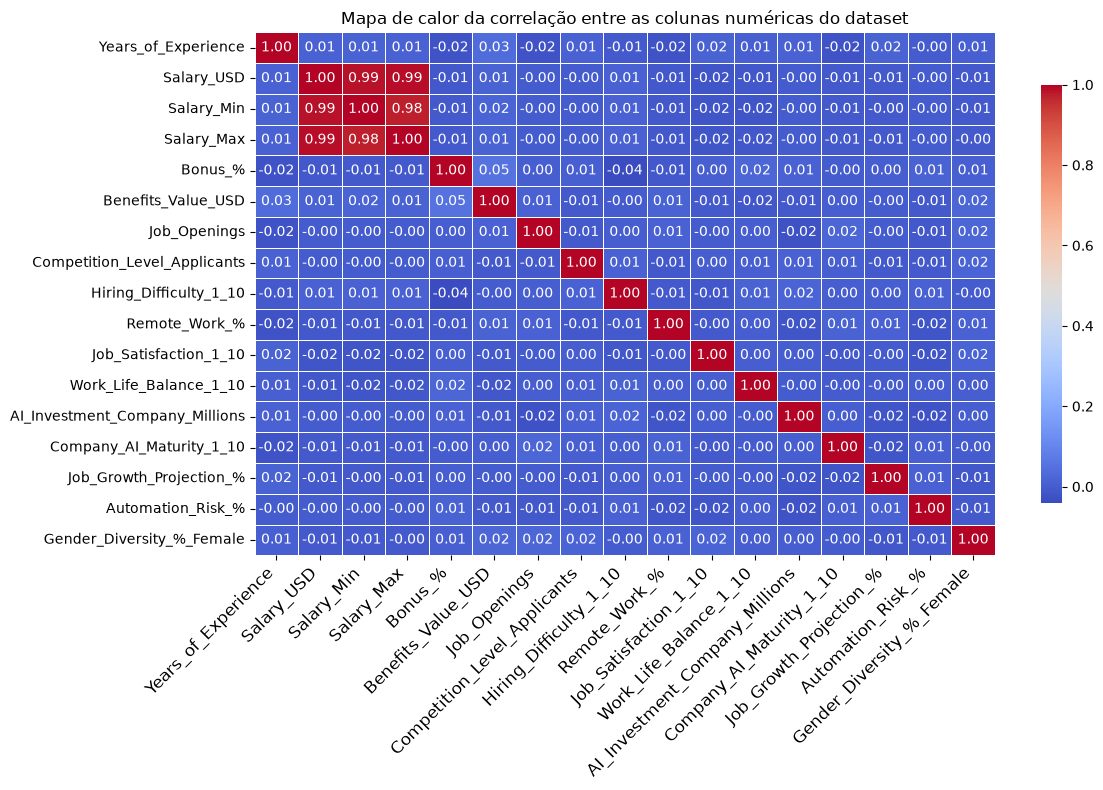

In [5]:
colunas_numericas = dataset.select_dtypes(include=np.number).columns.tolist() #Selecionando colunas numéricas do dataset

print(f"Colunas numéricas do dataset: \n{colunas_numericas}")

corr = dataset[colunas_numericas].corr() #Calculando a correlação entre as colunas numéricas do dataset

print("Gerando o mapa de calor da correlação entre as colunas numéricas do dataset...")

plt.figure(figsize=(12, 8)) #Definindo o tamanho da figura do mapa de calor

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f",
linewidths=0.5, #Adiciona uma linha de separação entre os quadrados
annot_kws={"size": 10},#Reduz o tamanho dos números internos
cbar_kws={"shrink": 0.8}) #Ajusta o tamanho da barra de escala lateral

plt.xticks(rotation=45,ha='right',fontsize=12) 
plt.yticks(fontsize=10)

plt.title("Mapa de calor da correlação entre as colunas numéricas do dataset") 

plt.tight_layout() #Ajusta o layout da figura para evitar sobreposição de elementos
plt.show()

Bloco 1

Correlações e Distribuições Numéricas

In [6]:
colunas_foco = [
    'Salary_USD', 'Bonus_%', 'Remote_Work_%', 
    'Job_Satisfaction_1_10', 'Work_Life_Balance_1_10', 
    'AI_Investment_Company_Millions', 'Company_AI_Maturity_1_10',
    'Automation_Risk_%', 'Hiring_Difficulty_1_10', 'Competition_Level_Applicants'
]


O Efeito do Home Office. Qual a exata correlação matemática entre o percentual de trabalho remoto, a satisfação geral e o equilíbrio pessoal ?

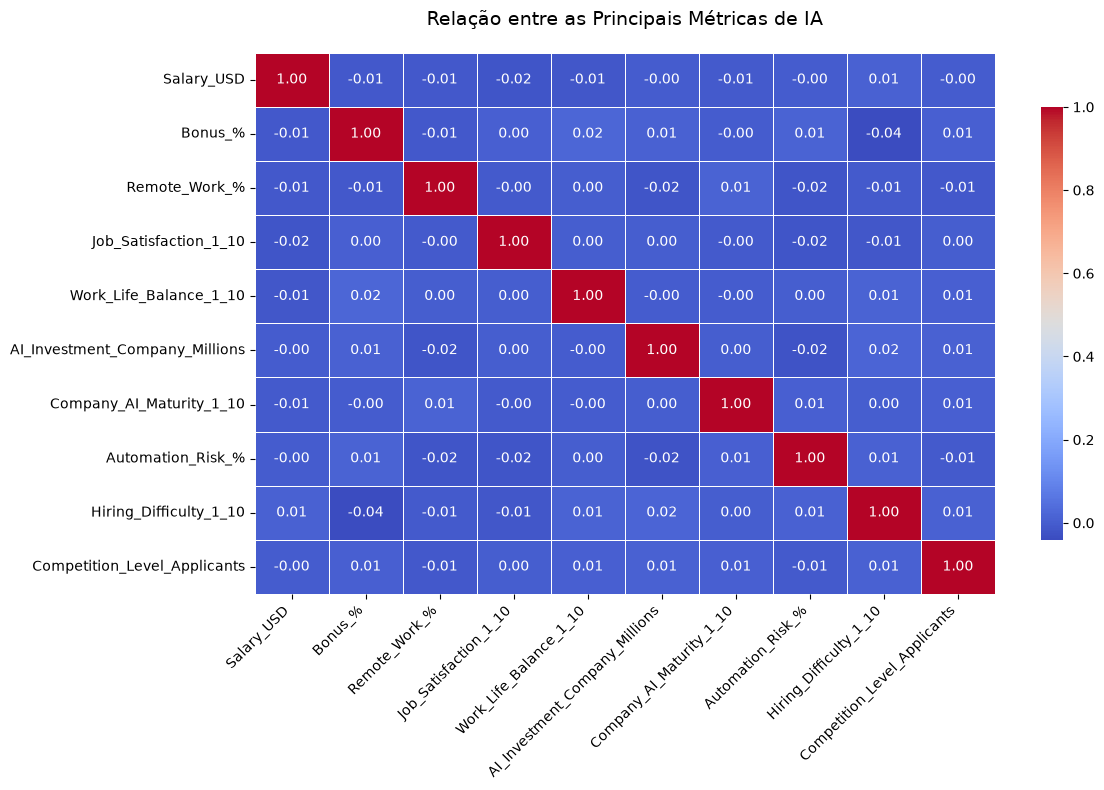

In [7]:
plt.figure(figsize=(12, 8)) 
corr = dataset[colunas_foco].corr()
sns.heatmap(
    corr,annot=True,cmap='coolwarm',fmt=".2f",
    linewidths=0.5,annot_kws={"size": 10},cbar_kws={"shrink": 0.8}
)

plt.title("Relação entre as Principais Métricas de IA",pad = 20, fontsize = 14)
plt.xticks(rotation=45,ha='right',fontsize=10) #Ajustando a rotação e alinhamento dos rótulos do eixo x
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

Conclusões
O mapa de calor revela uma ausência quase total de correlação linear entre as métricas, com todos os cruzamentos muito próximos de zero. Isso gera dois grandes insights práticos para a nossa análise: primeiro, aumentar o percentual de home office não melhora automaticamente o equilíbrio pessoal ou a satisfação do profissional de IA; segundo, um alto investimento da empresa não garante a oferta de salários maiores, comprovando que o mercado de tecnologia é complexo e os benefícios não dependem de fatores isolados.

O Paradoxo do Investimento. Maior investimento corporativo em IA empurra os salários matematicamente para cima ?

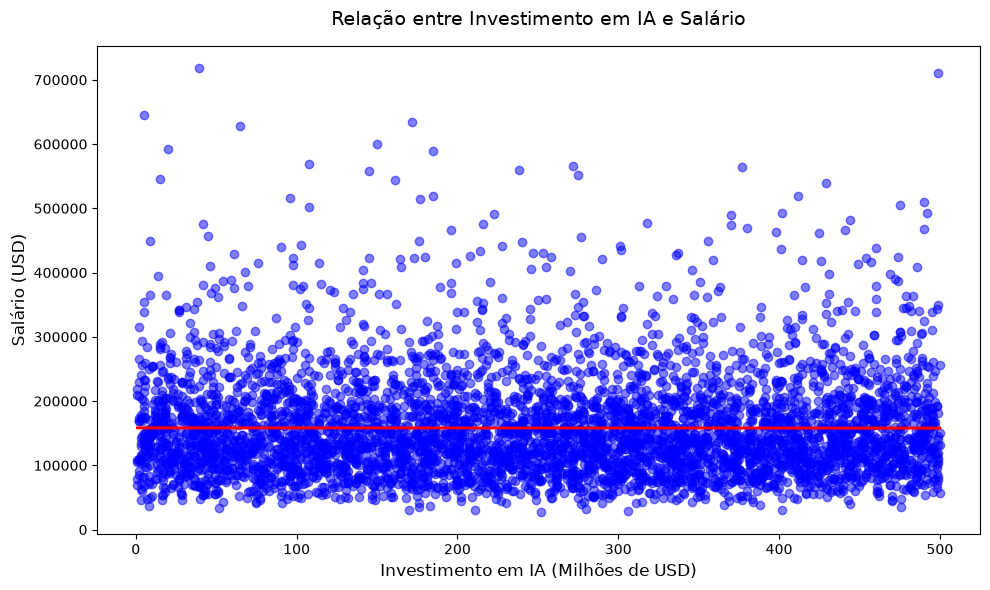

In [8]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data= dataset,
    x = 'AI_Investment_Company_Millions',
    y = 'Salary_USD',
    scatter_kws={'color': 'blue', 'alpha': 0.5},
    line_kws={'color': 'red', 'linewidth': 2}
)

plt.title("Relação entre Investimento em IA e Salário", pad = 15,fontsize = 14) # pad é o espaçamento entre o título e o gráfico
plt.xlabel("Investimento em IA (Milhões de USD)", fontsize = 12)
plt.ylabel("Salário (USD)", fontsize = 12)
plt.tight_layout()
plt.show()



Conclusões
O gráfico de regressão comprova visualmente o "Paradoxo do Investimento". A linha de tendência vermelha totalmente horizontal demonstra que o aumento do capital injetado em IA pelas empresas não gera nenhum impacto matemático na elevação dos salários oferecidos. A nuvem de pontos azuis distribuída de forma homogênea revela que corporações com orçamentos modestos pagam remunerações tão competitivas (atingindo picos acima de 700 mil dólares) quanto aquelas que investem até 500 milhões de dólares, provando que o mercado dita as regras salariais independentemente do tamanho do cofre da contratante.

O Prémio pela Escassez : Vagas com alta dificuldade de contratação pagam maiores bônus ?

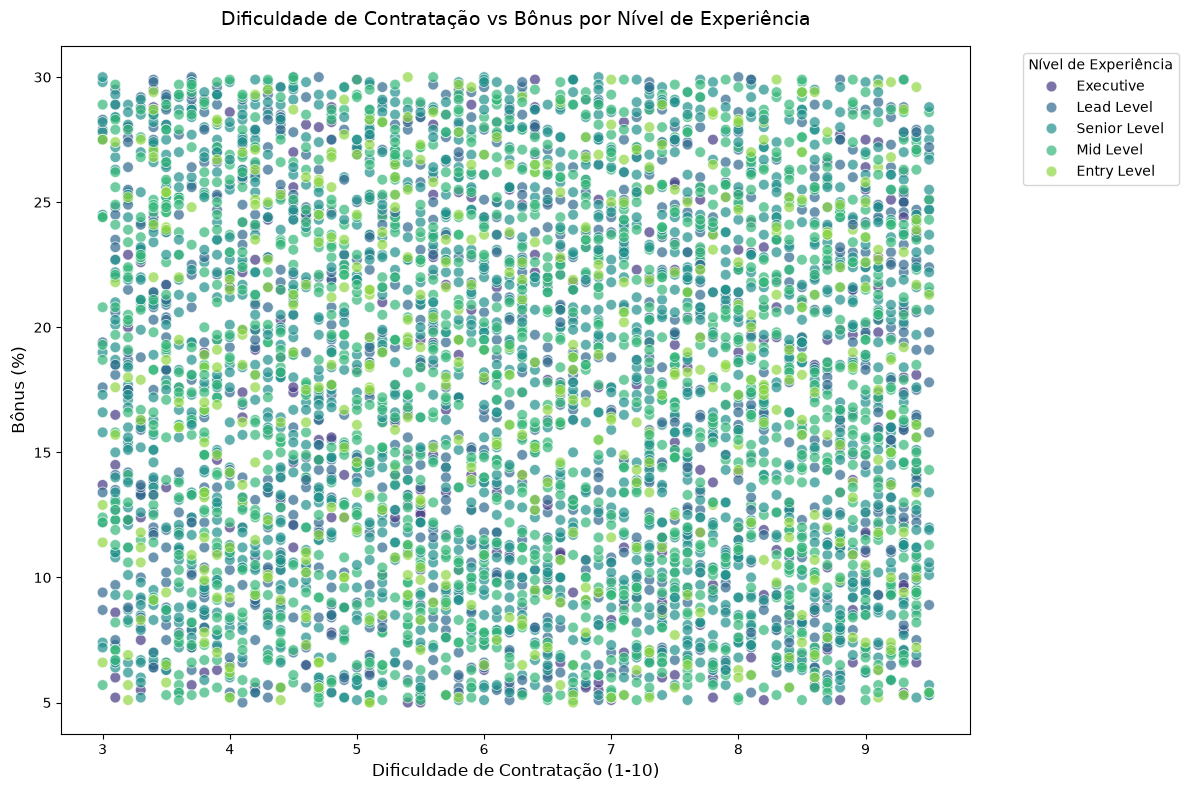

In [9]:
plt.figure(figsize=(12, 8)) 
sns.scatterplot(
    data=dataset,
    x = "Hiring_Difficulty_1_10",
    y = "Bonus_%",
    hue = "Experience_Level",
    palette = "viridis",
    alpha = 0.7, #Alpha define a transparência dos pontos no gráfico, onde 0 é totalmente transparente e 1 é totalmente opaco
    s = 60 #S define o tamanho dos pontos no gráfico
)

plt.title("Dificuldade de Contratação vs Bônus por Nível de Experiência", pad = 15, fontsize = 14)
plt.xlabel("Dificuldade de Contratação (1-10)", fontsize = 12)
plt.ylabel("Bônus (%)", fontsize = 12)
plt.legend(title = "Nível de Experiência", bbox_to_anchor=(1.05, 1), loc='upper left') #
#Bbox_to_anchor define a posição da legenda em relação ao gráfico, onde (1.05, 1) significa que a legenda estará à direita do gráfico e alinhada ao topo
#loc é posição da legenda em relação ao gráfico
plt.tight_layout()
plt.show()


Conclusões
O gráfico de dispersão derruba a tese do "Prêmio pela Escassez". A nuvem de pontos forma um padrão totalmente aleatório, provando que vagas extremamente difíceis de preencher (nível 9) oferecem bônus mínimos na faixa de 5%, enquanto vagas mais fáceis (nível 3) podem chegar a pagar o teto de 30% de bonificação. Além disso, a mistura homogênea das cores evidencia que essa desconexão entre a dificuldade de contratação e as recompensas financeiras atinge o mercado inteiro de forma regular, nivelando as oportunidades desde os profissionais juniores (Entry Level) até os cargos executivos.

A Saturação. Como se concentra a frequência do volume de candidatos nas vagas de IA analisadas?

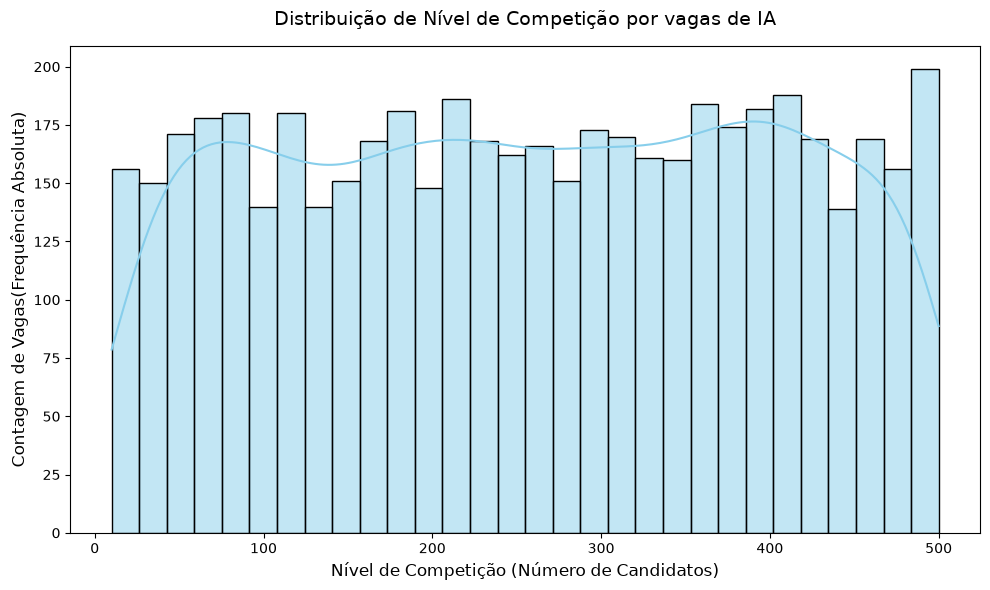

In [10]:
plt.figure(figsize = (10,6))

sns.histplot(
    data = dataset,
    x = "Competition_Level_Applicants",
    bins = 30, #Número de bins (ou intervalos) no histograma
    kde = True,
    color = 'skyblue',
)

plt.title("Distribuição de Nível de Competição por vagas de IA", pad = 15, fontsize = 14)
plt.xlabel("Nível de Competição (Número de Candidatos)", fontsize = 12)
plt.ylabel("Contagem de Vagas(Frequência Absoluta)", fontsize = 12)
plt.tight_layout()
plt.show()

Conclusões : 
O histograma revela que não existe um padrão único de concentração ou saturação no mercado de IA, apresentando uma distribuição estatisticamente regularizada. A constância na altura das barras e a linha de densidade horizontal demonstram que o volume de concorrência é altamente fragmentado: a quantidade de vagas que atraem 50 candidatos é praticamente a mesma daquelas que atraem 400 ou 450 concorrentes. Isso indica que a competição não afunila em um gargalo específico, mas sim se espalha de forma consistente por nichos de baixa e alta disputa.